In [ ]:
import os, glob, json
from google.colab import drive
drive.mount('/content/drive')

!pip -q install scanpy anndata

WORK  = '/content/drive/MyDrive/scBERT_run'
DATA  = f'{WORK}/data'
RES   = f'{WORK}/results'
BENCH = f'{WORK}/benchmarks'
os.makedirs(BENCH, exist_ok=True)

DATASETS = {
    'synthetic_holdout': f'{DATA}/synthetic_scbert.h5ad',
    'synthetic_v2':      f'{DATA}/synthetic_v2_scbert.h5ad',
    'baron_holdout':     f'{DATA}/baron_scbert.h5ad',
    'zheng_ref10':       f'{DATA}/zheng68k_scbert.h5ad',
    'zheng_ref10_cont':  f'{DATA}/zheng68k_scbert.h5ad',
}
for name, path in DATASETS.items():
    split = f'{RES}/{name}/fold0/split.npz'
    scb   = f'{RES}/{name}/fold0/metrics.json'
    print(f'{name:18s} data {"OK" if os.path.exists(path) else "MISSING":7s} '
          f'split {"OK" if os.path.exists(split) else "not yet":7s} '
          f'scBERT result {"OK" if os.path.exists(scb) else "not yet"}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
synthetic_holdout  data OK      split OK      scBERT result OK
synthetic_v2       data OK      split OK      scBERT result OK
baron_holdout      data OK      split OK      scBERT result OK
zheng_ref10        data OK      split OK      scBERT result OK
zheng_ref10_cont   data OK      split OK      scBERT result OK


In [ ]:
import time, numpy as np, pandas as pd, scanpy as sc, torch
from torch import nn
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)
torch.set_num_threads(os.cpu_count())

def load(path):
    ad = sc.read_h5ad(path)
    X = ad.X.tocsr() if sparse.issparse(ad.X) else sparse.csr_matrix(ad.X)
    names, y = np.unique(np.asarray(ad.obs['celltype']).astype(str), return_inverse=True)
    return X.astype(np.float32), y, names, ad.obs_names

def metrics(yt, pred, names, extra):
    n = len(names)
    return {**extra,
            'test_accuracy': accuracy_score(yt, pred),
            'test_macro_precision': precision_score(yt, pred, average='macro', zero_division=0),
            'test_macro_recall': recall_score(yt, pred, average='macro', zero_division=0),
            'test_macro_f1': f1_score(yt, pred, average='macro', zero_division=0),
            'test_weighted_f1': f1_score(yt, pred, average='weighted', zero_division=0),
            'per_class': classification_report(yt, pred, labels=range(n), target_names=names,
                                               output_dict=True, zero_division=0),
            'labels': names.tolist(),
            'confusion_matrix': confusion_matrix(yt, pred, labels=range(n)).tolist()}

def run_logreg(X, y, fit, val, test):
    best = None
    for C in [0.01, 0.1, 1.0]:
        t0 = time.time()
        clf = LogisticRegression(C=C, max_iter=1000, tol=1e-4)
        clf.fit(X[fit], y[fit])
        va = accuracy_score(y[val], clf.predict(X[val]))
        print(f'    logreg C={C:<5} val acc {va:.4f}  ({time.time() - t0:.0f}s)')
        if best is None or va > best[0]:
            best = (va, C, clf)
    va, C, clf = best
    return clf.predict(X[test]), {'best_val_acc': va, 'C': C}

def run_mlp(X, y, fit, val, test, n_cls, seed=2021, epochs=60, patience=6, bs=128):
    torch.manual_seed(seed); np.random.seed(seed)
    net = nn.Sequential(nn.Linear(X.shape[1], 256), nn.ReLU(), nn.Dropout(0.3),
                        nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n_cls))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    lossf = nn.CrossEntropyLoss()
    dense = lambda idx: torch.from_numpy(X[idx].toarray())
    def predict(idx):
        net.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(idx), 1024):
                out.append(net(dense(idx[i:i + 1024])).argmax(1).numpy())
        return np.concatenate(out)
    best_acc, best_state, bad, log = -1, None, 0, []
    for ep in range(1, epochs + 1):
        net.train(); order = np.random.permutation(fit); tot = 0.0
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            loss = lossf(net(dense(b)), torch.from_numpy(y[b]).long())
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        va = accuracy_score(y[val], predict(val)); log.append({'epoch': ep, 'train_loss': tot / len(fit), 'val_acc': va})
        if va > best_acc:
            best_acc, bad = va, 0; best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    print(f'    mlp: {len(log)} epochs, best val acc {best_acc:.4f}')
    return predict(test), {'best_val_acc': best_acc, 'epochs_run': len(log), 'log': log}

_js = lambda o: o.item() if hasattr(o, 'item') else str(o)
cache = {}
for name, path in DATASETS.items():
    split_p = f'{RES}/{name}/fold0/split.npz'
    if not os.path.exists(split_p):
        print(f'== {name}: scBERT split not saved yet, skipping (rerun this cell later)'); continue
    if path not in cache:
        cache[path] = load(path)
    X, y, names, cells = cache[path]
    s = np.load(split_p); fit, val, test = s['fit'], s['val'], s['test']
    print(f'\n== {name}: fit={len(fit)} val={len(val)} test={len(test)}, {len(names)} cell types')
    for model in ['logreg', 'mlp']:
        out = f'{BENCH}/{name}/{model}'
        if os.path.exists(f'{out}/metrics.json'):
            print(f'  {model}: done, skipping'); continue
        os.makedirs(out, exist_ok=True)
        t0 = time.time()
        pred, extra = run_logreg(X, y, fit, val, test) if model == 'logreg' else \
                      run_mlp(X, y, fit, val, test, len(names))
        m = metrics(y[test], pred, names, {'model': model, 'experiment': name, 'n_fit': len(fit),
                                           'n_val': len(val), 'n_test': len(test),
                                           'train_minutes': (time.time() - t0) / 60, **extra})
        json.dump(m, open(f'{out}/metrics.json', 'w'), indent=1, default=_js)
        pd.DataFrame({'cell': cells[test], 'true': names[y[test]], 'pred': names[pred]}).to_csv(
            f'{out}/test_predictions.csv', index=False)
        print(f'  {model}: TEST acc {m["test_accuracy"]:.4f}  macro P {m["test_macro_precision"]:.4f}  '
              f'macro R {m["test_macro_recall"]:.4f}  macro F1 {m["test_macro_f1"]:.4f}  '
              f'({m["train_minutes"]:.1f} min)')


== synthetic_holdout: fit=1200 val=200 test=600, 6 cell types
  logreg: done, skipping
  mlp: done, skipping

== synthetic_v2: fit=2000 val=300 test=600, 6 cell types
    logreg C=0.01  val acc 1.0000  (11s)
    logreg C=0.1   val acc 1.0000  (6s)
    logreg C=1.0   val acc 1.0000  (4s)
  logreg: TEST acc 1.0000  macro P 1.0000  macro R 1.0000  macro F1 1.0000  (0.3 min)
    mlp: 7 epochs, best val acc 1.0000
  mlp: TEST acc 1.0000  macro P 1.0000  macro R 1.0000  macro F1 1.0000  (0.2 min)

== baron_holdout: fit=6355 val=500 test=1714, 14 cell types
  logreg: done, skipping
  mlp: done, skipping

== zheng_ref10: fit=6345 val=500 test=8000, 11 cell types
  logreg: done, skipping
  mlp: done, skipping

== zheng_ref10_cont: fit=6345 val=500 test=8000, 11 cell types
    logreg C=0.01  val acc 0.6580  (47s)
    logreg C=0.1   val acc 0.6500  (52s)
    logreg C=1.0   val acc 0.6540  (35s)
  logreg: TEST acc 0.6784  macro P 0.6265  macro R 0.5284  macro F1 0.5524  (2.2 min)
    mlp: 7 epoch


######## synthetic_holdout: per-class F1 on the same test cells
        test cells  scBERT  logreg    mlp
type_A         179    0.46   0.829  0.678
type_B         140    0.00   0.816  0.652
type_C         110    0.00   0.991  0.914
type_D          82    0.00   0.952  0.841
type_E          50    0.00   0.709  0.241
type_F          39    0.00   0.932  0.756


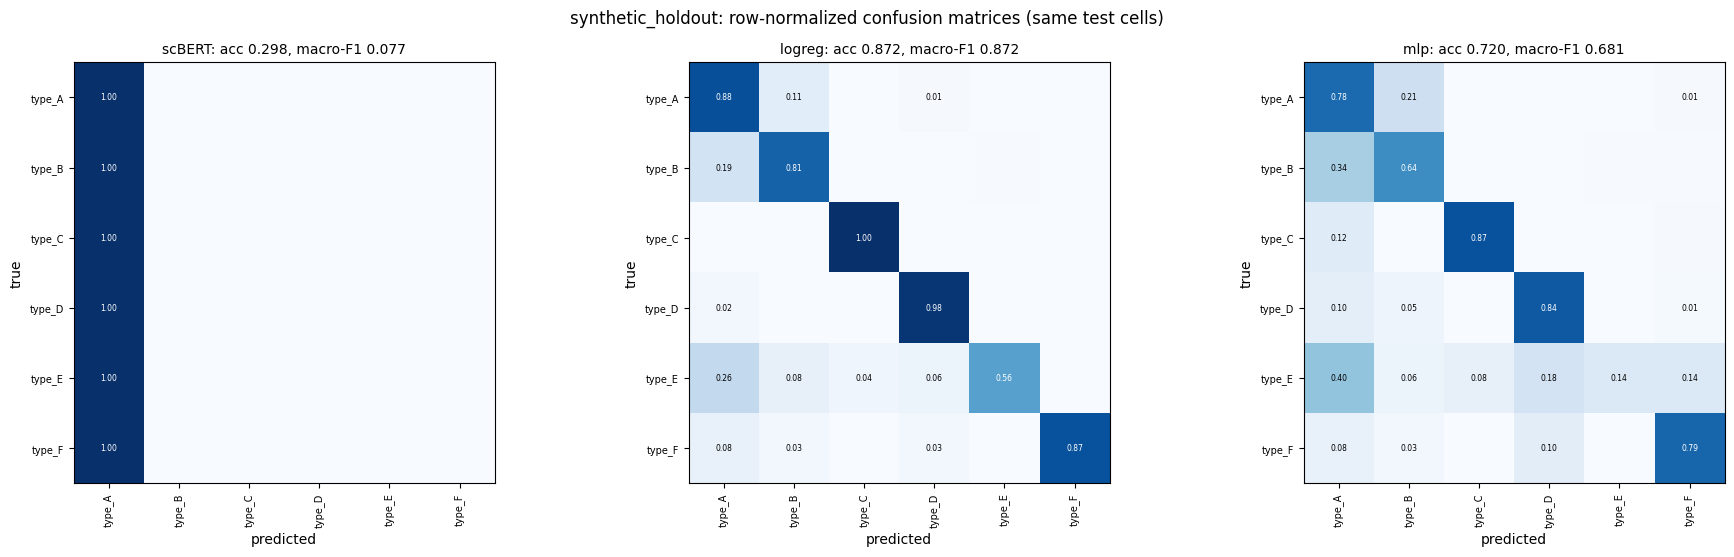


######## synthetic_v2: per-class F1 on the same test cells
        test cells  scBERT  logreg  mlp
type_A         170     1.0     1.0  1.0
type_B         150     1.0     1.0  1.0
type_C         112     1.0     1.0  1.0
type_D          78     1.0     1.0  1.0
type_E          55     1.0     1.0  1.0
type_F          35     1.0     1.0  1.0


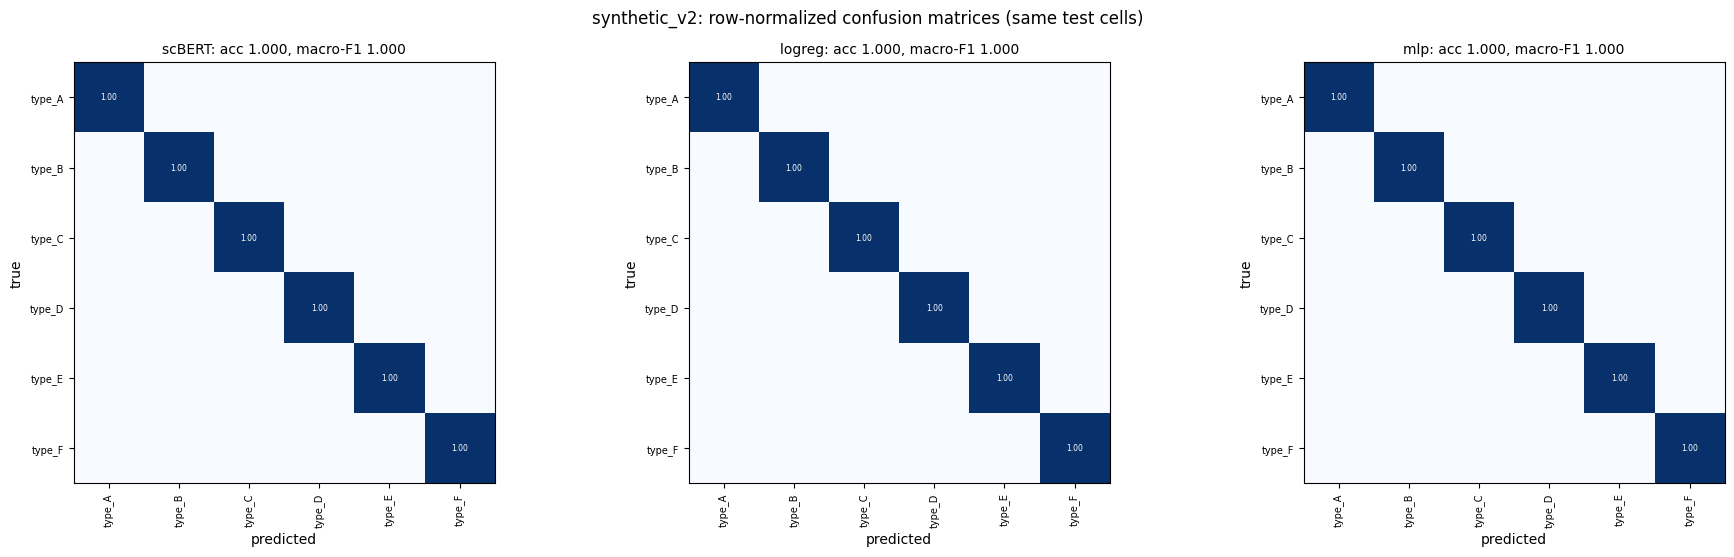


######## baron_holdout: per-class F1 on the same test cells
                    test cells  scBERT  logreg    mlp
beta                       505   0.984   0.991  0.994
alpha                      465   0.980   0.989  0.993
ductal                     215   0.960   0.988  0.993
acinar                     192   0.956   0.987  0.987
delta                      120   0.946   0.971  0.975
activated_stellate          57   0.908   0.982  0.982
gamma                       51   0.854   1.000  1.000
endothelial                 50   0.911   0.969  0.980
quiescent_stellate          35   0.758   0.848  0.866
macrophage                  11   0.900   0.952  1.000
mast                         5   0.000   0.909  1.000
epsilon                      4   0.000   0.000  0.667
schwann                      3   0.000   1.000  1.000
t_cell                       1   0.000   0.000  1.000


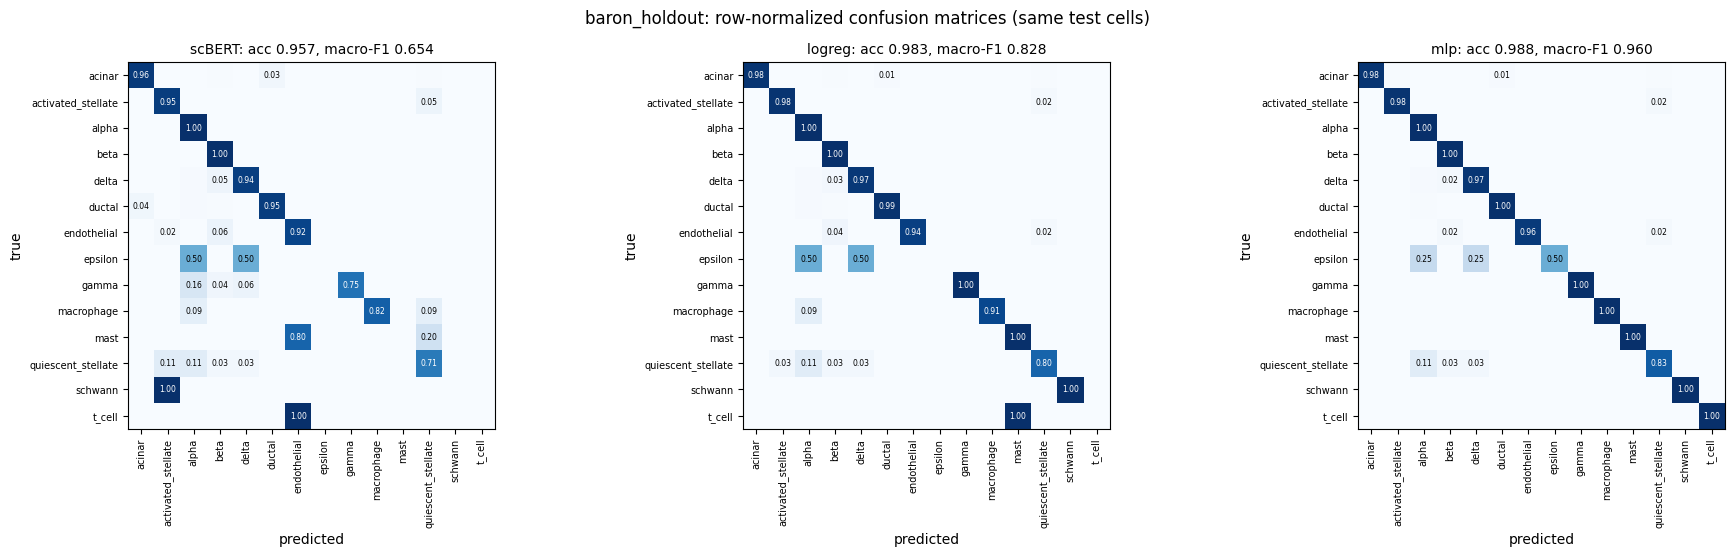


######## zheng_ref10: per-class F1 on the same test cells
                              test cells  scBERT  logreg    mlp
CD8+ Cytotoxic T                    2426   0.482   0.685  0.672
CD8+/CD45RA+ Naive Cytotoxic        1945   0.306   0.665  0.658
CD56+ NK                            1026   0.000   0.895  0.899
CD4+/CD25 T Reg                      723   0.000   0.474  0.476
CD19+ B                              687   0.000   0.777  0.743
CD4+/CD45RO+ Memory                  357   0.000   0.246  0.226
CD14+ Monocyte                       333   0.000   0.850  0.857
Dendritic                            245   0.000   0.688  0.708
CD4+/CD45RA+/CD25- Naive T           219   0.000   0.043  0.033
CD34+                                 28   0.000   0.756  0.809
CD4+ T Helper2                        11   0.000   0.000  0.000


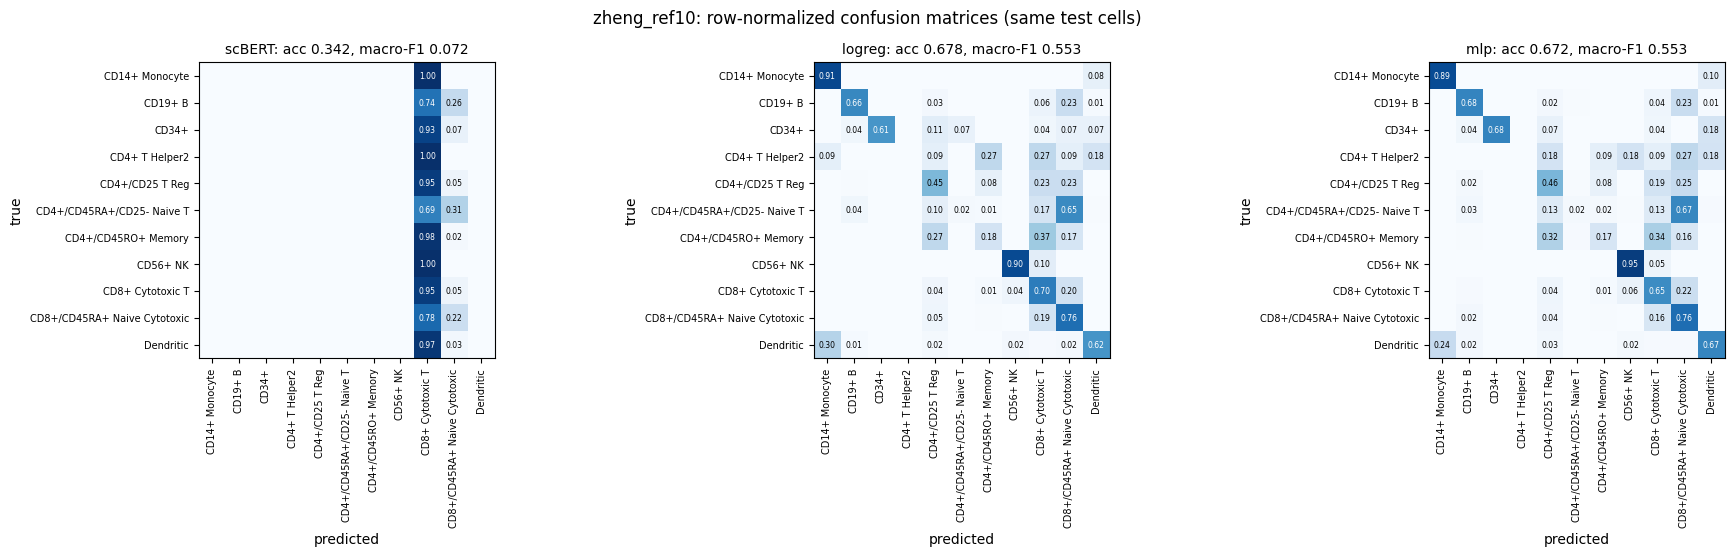


######## zheng_ref10_cont: per-class F1 on the same test cells
                              test cells  scBERT  logreg    mlp
CD8+ Cytotoxic T                    2426   0.626   0.685  0.635
CD8+/CD45RA+ Naive Cytotoxic        1945   0.672   0.665  0.689
CD56+ NK                            1026   0.850   0.895  0.870
CD4+/CD25 T Reg                      723   0.085   0.476  0.452
CD19+ B                              687   0.773   0.777  0.786
CD4+/CD45RO+ Memory                  357   0.000   0.245  0.000
CD14+ Monocyte                       333   0.757   0.848  0.849
Dendritic                            245   0.663   0.686  0.615
CD4+/CD45RA+/CD25- Naive T           219   0.000   0.043  0.000
CD34+                                 28   0.000   0.756  0.000
CD4+ T Helper2                        11   0.000   0.000  0.000


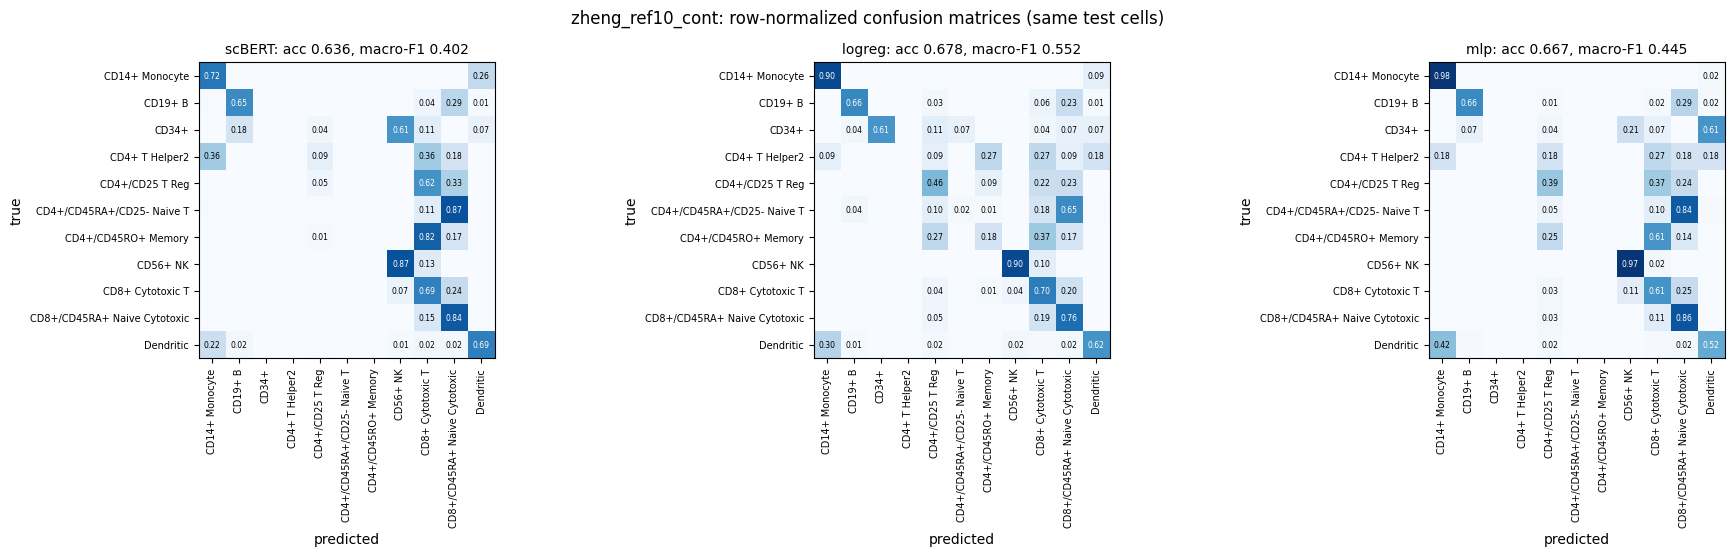


================ BENCHMARK COMPARISON (test set) ================
       experiment  model  test cells  accuracy  macro precision  macro recall  macro F1  weighted F1  train minutes hardware
synthetic_holdout scBERT         600    0.2983           0.0497        0.1667    0.0766       0.1371        11.0689   L4 GPU
synthetic_holdout logreg         600    0.8717           0.9141        0.8495    0.8715       0.8693         0.6123      CPU
synthetic_holdout    mlp         600    0.7200           0.7768        0.6781    0.6806       0.7063         0.3431      CPU
     synthetic_v2 scBERT         600    1.0000           1.0000        1.0000    1.0000       1.0000        36.4630   L4 GPU
     synthetic_v2 logreg         600    1.0000           1.0000        1.0000    1.0000       1.0000         0.3487      CPU
     synthetic_v2    mlp         600    1.0000           1.0000        1.0000    1.0000       1.0000         0.1886      CPU
    baron_holdout scBERT        1714    0.9574           0

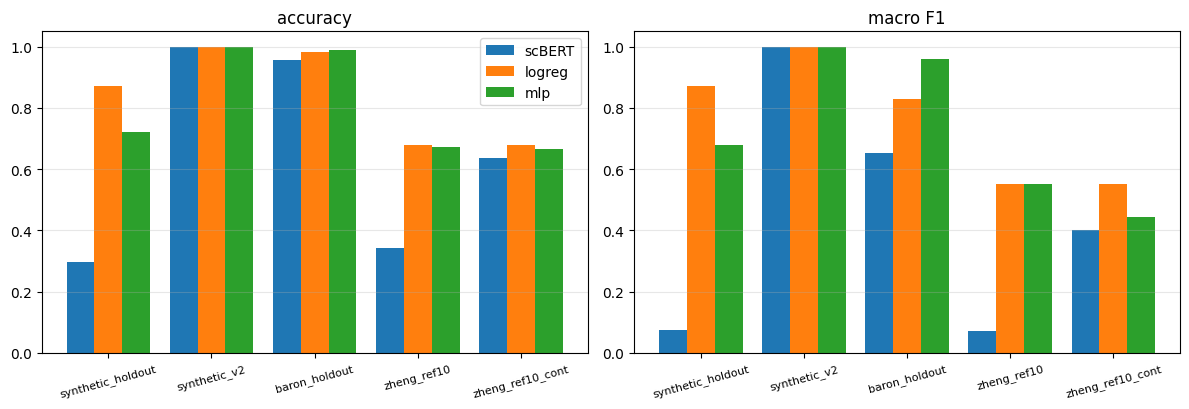

saved: /content/drive/MyDrive/scBERT_run/benchmarks/benchmark_comparison.csv, *_per_class_f1.csv, *_confusion_matrices.png, benchmark_bars.png


In [ ]:
import matplotlib.pyplot as plt
MODELS = ['scBERT', 'logreg', 'mlp']

def load_metrics(name, model):
    p = f'{RES}/{name}/fold0/metrics.json' if model == 'scBERT' else f'{BENCH}/{name}/{model}/metrics.json'
    return json.load(open(p)) if os.path.exists(p) else None

rows = []
for name in DATASETS:
    ms = {mo: load_metrics(name, mo) for mo in MODELS}
    if not any(ms.values()):
        continue
    for mo, m in ms.items():
        if m is None:
            continue
        minutes = sum(l.get('minutes', 0) for l in m['log']) if mo == 'scBERT' else m['train_minutes']
        rows.append({'experiment': name, 'model': mo, 'test cells': m['n_test'],
                     'accuracy': m['test_accuracy'], 'macro precision': m['test_macro_precision'],
                     'macro recall': m['test_macro_recall'], 'macro F1': m['test_macro_f1'],
                     'weighted F1': m['test_weighted_f1'], 'train minutes': minutes,
                     'hardware': 'L4 GPU' if mo == 'scBERT' else 'CPU'})

    done = {mo: m for mo, m in ms.items() if m}
    labels = next(iter(done.values()))['labels']
    pc = pd.DataFrame({mo: [m['per_class'][l]['f1-score'] for l in labels] for mo, m in done.items()}, index=labels)
    pc.insert(0, 'test cells', [int(next(iter(done.values()))['per_class'][l]['support']) for l in labels])
    print(f'\n######## {name}: per-class F1 on the same test cells')
    print(pc.sort_values('test cells', ascending=False).round(3).to_string())
    pc.to_csv(f'{BENCH}/{name}_per_class_f1.csv')

    fig, axs = plt.subplots(1, len(done), figsize=(6.2 * len(done), 5.6), squeeze=False)
    for ax, (mo, m) in zip(axs[0], done.items()):
        cm = np.array(m['confusion_matrix'], float); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
        L = m['labels']; ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=90, fontsize=7)
        ax.set_yticks(range(len(L))); ax.set_yticklabels(L, fontsize=7)
        for i in range(len(L)):
            for j in range(len(L)):
                if cmn[i, j] >= 0.01:
                    ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=5.5,
                            color='white' if cmn[i, j] > .5 else 'black')
        ax.set_title(f'{mo}: acc {m["test_accuracy"]:.3f}, macro-F1 {m["test_macro_f1"]:.3f}', fontsize=10)
        ax.set_xlabel('predicted'); ax.set_ylabel('true')
    fig.suptitle(f'{name}: row-normalized confusion matrices (same test cells)')
    fig.tight_layout(); fig.savefig(f'{BENCH}/{name}_confusion_matrices.png', dpi=200); plt.show()

table = pd.DataFrame(rows)
table.to_csv(f'{BENCH}/benchmark_comparison.csv', index=False)
pd.set_option('display.width', 250)
print('\n================ BENCHMARK COMPARISON (test set) ================')
print(table.round(4).to_string(index=False))

exps = table['experiment'].unique()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric in zip(axs, ['accuracy', 'macro F1']):
    w = 0.27
    for k, mo in enumerate(MODELS):
        vals = [table[(table.experiment == e) & (table.model == mo)][metric].max() for e in exps]
        ax.bar(np.arange(len(exps)) + (k - 1) * w, np.nan_to_num(vals), w, label=mo)
    ax.set_xticks(range(len(exps))); ax.set_xticklabels(exps, rotation=15, fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_title(metric); ax.grid(axis='y', alpha=.3)
axs[0].legend(); fig.tight_layout(); fig.savefig(f'{BENCH}/benchmark_bars.png', dpi=200); plt.show()
print(f'saved: {BENCH}/benchmark_comparison.csv, *_per_class_f1.csv, *_confusion_matrices.png, benchmark_bars.png')